## 0. 数据准备：CSV → MySQL

原始 CSV 的入库**不在这个 notebook 里做**，而是交给独立脚本：

```bash
python scripts/load_to_mysql.py
```

脚本负责：读 `.env` → 建库 `data_analysis` → `to_sql` 写入 `video_games_sales` 表
→ 回查行数与销量总额校验。

**为什么拆出去：**

1. 入库是**一次性的准备工作**，不属于分析过程；放在 notebook 里，每次「Run All」
   都要重跑一遍全量写入，纯属浪费。
2. 入库失败（连不上 MySQL、密码错、驱动缺失）时，命令行里能直接看到一条清晰的
   报错和修复提示，而不是埋在几十行 notebook 输出中间。
3. notebook 只保留「读 → 清洗 → 分析 → 画图」这条主线，读起来更连贯。

下面这格只做一件事：连上 MySQL，把表读成 `df`。

In [37]:
from sqlalchemy import create_engine
import pandas as pd
import os
from dotenv import load_dotenv

# 自动加载 .env（用户名 / 密码不写死在代码里，也不进版本库）
load_dotenv()

pd.set_option('display.max_columns', None)

# 从环境变量读取连接信息
user = os.getenv("DB_USER")
password = os.getenv("DB_PASSWORD")
host = os.getenv("DB_HOST")
port = os.getenv("DB_PORT")

# 建引擎：相当于「自动连接池管理器」，负责开连接、复用、关闭
# 格式：mysql+pymysql://用户名:密码@主机:端口/数据库名
engine = create_engine(
    f"mysql+pymysql://{user}:{password}@{host}:{port}/data_analysis"
)

# 从库里读回原始表（表名含点号，SQL 里必须用反引号包住）
df = pd.read_sql("SELECT * FROM data_analysis.`video_games_sales`;", engine)

print(df.head(3))
print("\n数据类型：")
print(df.dtypes)

                Name Platform  Year_of_Release     Genre Publisher  NA_Sales  \
0         Wii Sports      Wii           2006.0    Sports  Nintendo     41.36   
1  Super Mario Bros.      NES           1985.0  Platform  Nintendo     29.08   
2     Mario Kart Wii      Wii           2008.0    Racing  Nintendo     15.68   

   EU_Sales  JP_Sales  Other_Sales  Global_Sales  Critic_Score  Critic_Count  \
0     28.96      3.77         8.45         82.53          76.0          51.0   
1      3.58      6.81         0.77         40.24           NaN           NaN   
2     12.76      3.79         3.29         35.52          82.0          73.0   

  User_Score  User_Count Developer Rating  
0          8       322.0  Nintendo      E  
1       None         NaN      None   None  
2        8.3       709.0  Nintendo      E  

数据类型：
Name                object
Platform            object
Year_of_Release    float64
Genre               object
Publisher           object
NA_Sales           float64
EU_Sales     

In [38]:
print(df.shape)
print('##################')
print(df.info())

(16719, 16)
##################
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16719 entries, 0 to 16718
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16717 non-null  object 
 1   Platform         16719 non-null  object 
 2   Year_of_Release  16450 non-null  float64
 3   Genre            16717 non-null  object 
 4   Publisher        16665 non-null  object 
 5   NA_Sales         16719 non-null  float64
 6   EU_Sales         16719 non-null  float64
 7   JP_Sales         16719 non-null  float64
 8   Other_Sales      16719 non-null  float64
 9   Global_Sales     16719 non-null  float64
 10  Critic_Score     8137 non-null   float64
 11  Critic_Count     8137 non-null   float64
 12  User_Score       10015 non-null  object 
 13  User_Count       7590 non-null   float64
 14  Developer        10096 non-null  object 
 15  Rating           9950 non-null   object 
dtypes: float64(9), object(7)
me

In [39]:
print(df.describe())

       Year_of_Release      NA_Sales      EU_Sales      JP_Sales  \
count     16450.000000  16719.000000  16719.000000  16719.000000   
mean       2006.487356      0.263330      0.145025      0.077602   
std           5.878995      0.813514      0.503283      0.308818   
min        1980.000000      0.000000      0.000000      0.000000   
25%        2003.000000      0.000000      0.000000      0.000000   
50%        2007.000000      0.080000      0.020000      0.000000   
75%        2010.000000      0.240000      0.110000      0.040000   
max        2020.000000     41.360000     28.960000     10.220000   

        Other_Sales  Global_Sales  Critic_Score  Critic_Count    User_Count  
count  16719.000000  16719.000000   8137.000000   8137.000000   7590.000000  
mean       0.047332      0.533543     68.967679     26.360821    162.229908  
std        0.186710      1.547935     13.938165     18.980495    561.282326  
min        0.000000      0.010000     13.000000      3.000000      4.000000

**几个用到的概念**

- **`create_engine`**：创建一个数据库连接引擎（打通 Python 和 MySQL 的通道），
  只在开头调用一次；之后 `read_sql` 直接复用它，不用手动 `close()`。
- **`df.to_sql(con=...)`**：`con` 不是独立函数，而是 `to_sql` 的参数名，用来指定
  往哪个连接里写。`if_exists` 可选 `replace` / `append` / `fail`，`index=False`
  表示不把 pandas 行索引写成一列，`chunksize` 分块写入更稳。这一段现在在
  `scripts/load_to_mysql.py` 里。
- **`text()`**：包装一段 SQL 交给连接执行。SQLAlchemy 2.x 的 `connect()` 默认开事务，
  `execute()` 只把语句放进草稿区，要 `commit()` 才真正生效——建库时踩过这个坑。
- **反引号 `\``**：SQL 的标识符引用符，告诉数据库「这是一个完整名字，别拆开」。
  表名叫 `video_games_sales` 时用不上，但一旦名字里带点号就必须加。

# 缺失值检查

In [40]:
import pandas as pd
import seaborn as sns

import matplotlib.pyplot as plt

# 1. 复制数据，避免污染原始 df
df_analysis = df.copy()

# 2. 检查缺失值和异常值
# 定义哪些字符串要被当作缺失（可按需增删）
NA_TOKENS = {'', 'N/A', 'NA', 'n/a', 'TBD', 'tbd', 'Unknown', 'unknown', 'NULL', 'null', '-', '?'}

def missing_report(df, tokens=NA_TOKENS):
    # 真空值（None / NaN / NaT）
    is_null = df.isna()
    # 字符串形式的缺失
    is_token = df.apply(lambda s: s.astype('string').str.strip().isin(tokens))
    # 二者取并集（同一格不会既是 NaN 又是字符串，但用 | 更严谨）
    real = is_null | is_token

    report = pd.DataFrame({
        'isnull显示': is_null.sum(),
        '字面量':     is_token.sum(),
        '实际缺失':   real.sum(),
        '缺失率%':    (real.mean() * 100).round(2), #利用bool的0，1把问题转换成概率问题
    })  #pandas 的 read_csv 默认就把 "N/A" 当缺失值
    report = report[report['实际缺失'] > 0].sort_values('实际缺失', ascending=False)
    return report

#`is_null.sum()`、`is_token.sum()` 是**按列求和**，pandas 按列求和之后，**返回结果的索引，就是原来 df 的列名**。
print('缺失值统计（含字面量）：')
su = missing_report(df_analysis)
display(su)

print(f"isnull 能看到：{su['isnull显示'].sum()} 个")
print(f"被字符串藏起来：{su['字面量'].sum()} 个")
print(f"真实缺失总计：  {su['实际缺失'].sum()} 个")


# ---------- ① 16 列完全相同的整行 ----------
print('完全重复行数：', df_analysis.duplicated().sum())
exact = df_analysis[df_analysis.duplicated(keep=False)].sort_values(['Name', 'Platform'])
display(exact)

# ---------- ② 同名同平台多行（业务重复）----------
key = ['Name', 'Platform']
dup = df_analysis[df_analysis.duplicated(subset=key, keep=False)].sort_values(key)
#默认是 `dropna=True`：分组时，只要分组 key 里有 NaN，直接丢掉这一行，不参与分组
print('业务重复行数：', len(dup), '｜涉及组数：', dup.groupby(key, dropna=False).ngroups)

cols = ['Name', 'Platform', 'Year_of_Release',  'NA_Sales', 'EU_Sales',
        'JP_Sales', 'Other_Sales', 'Global_Sales',
        'Critic_Score', 'Critic_Count', 'User_Score', 'User_Count']
display(dup)

# ---------- ③ 同名同平台、但年份不同（大概率是同名不同作）----------
nuniq = df_analysis.groupby(key, dropna=False)['Year_of_Release'].nunique()
conflict_keys = nuniq[nuniq > 1].index
conflict = df_analysis.set_index(key).loc[conflict_keys].reset_index().sort_values(key)
print('年份冲突的组数：', len(conflict_keys))
display(conflict[cols])

缺失值统计（含字面量）：


,isnull显示,字面量,实际缺失,缺失率%
User_Score,6704,2425,9129,54.60
User_Count,9129,0,9129,54.60
Critic_Score,8582,0,8582,51.33
Critic_Count,8582,0,8582,51.33
Rating,6769,0,6769,40.49
Developer,6623,0,6623,39.61
Year_of_Release,269,0,269,1.61
Publisher,54,201,255,1.53
Name,2,0,2,0.01
Genre,2,0,2,0.01


isnull 能看到：46716 个
被字符串藏起来：2626 个
真实缺失总计：  49342 个
完全重复行数： 0


,Name,Platform,Year_of_Release,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Developer,Rating


业务重复行数： 10 ｜涉及组数： 5


,Name,Platform,Year_of_Release,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Developer,Rating
604,Madden NFL 13,PS3,2012.0,Sports,Electronic Arts,2.11,0.22,0.00,0.23,2.56,83.0,22.0,5.5,101.0,EA Tiburon,E
16233,Madden NFL 13,PS3,2012.0,Sports,Electronic Arts,0.00,0.01,0.00,0.00,0.01,83.0,22.0,5.5,101.0,EA Tiburon,E
5973,Need for Speed: Most Wanted,PC,2005.0,Racing,Electronic Arts,0.02,0.23,0.00,0.04,0.29,82.0,19.0,8.5,525.0,Black Box,T
11716,Need for Speed: Most Wanted,PC,2012.0,Racing,Electronic Arts,0.00,0.06,0.00,0.02,0.08,82.0,19.0,8.5,525.0,Black Box,T
1190,Need for Speed: Most Wanted,X360,2012.0,Racing,Electronic Arts,0.62,0.78,0.01,0.15,1.56,83.0,54.0,8.5,134.0,EA Canada,T
1591,Need for Speed: Most Wanted,X360,2005.0,Racing,Electronic Arts,1.00,0.13,0.02,0.10,1.25,83.0,54.0,8.5,134.0,EA Canada,T
1745,Sonic the Hedgehog,PS3,2006.0,Platform,Sega,0.41,0.06,0.04,0.66,1.16,43.0,17.0,4.1,176.0,Sonic Team,E10+
4127,Sonic the Hedgehog,PS3,NaN,Platform,None,0.00,0.48,0.00,0.00,0.48,43.0,17.0,4.1,176.0,Sonic Team,E10+
659,None,GEN,1993.0,None,Acclaim Entertainment,1.78,0.53,0.00,0.08,2.39,NaN,NaN,None,NaN,None,None
14246,None,GEN,1993.0,None,Acclaim Entertainment,0.00,0.00,0.03,0.00,0.03,NaN,NaN,None,NaN,None,None


年份冲突的组数： 2


,Name,Platform,Year_of_Release,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count
0,Need for Speed: Most Wanted,PC,2005.0,0.02,0.23,0.00,0.04,0.29,82.0,19.0,8.5,525.0
1,Need for Speed: Most Wanted,PC,2012.0,0.00,0.06,0.00,0.02,0.08,82.0,19.0,8.5,525.0
2,Need for Speed: Most Wanted,X360,2012.0,0.62,0.78,0.01,0.15,1.56,83.0,54.0,8.5,134.0
3,Need for Speed: Most Wanted,X360,2005.0,1.00,0.13,0.02,0.10,1.25,83.0,54.0,8.5,134.0


# 缺失值处理

In [41]:
'''
缺失值处理方法--
1.删掉没有名字和没有游戏类型的数据

'''
#3.数据清洗
#3.0 统一缺失口径：把"看起来是数据、其实是缺失"的字符串变成真 NaN ----
# 注意：read_csv 默认会把 "N/A" 当缺失，但 "tbd" 不会，所以这步不能省
df_analysis['Year_of_Release'] = pd.to_numeric(df_analysis['Year_of_Release'], errors='coerce')
df_analysis['User_Score']      = pd.to_numeric(df_analysis['User_Score'],      errors='coerce')
df_analysis['Critic_Score']    = pd.to_numeric(df_analysis['Critic_Score'],    errors='coerce')
'''
**pd.to_numeric()**
专门用来把一列文本 / 字符串，转成数字（int /float）。
**errors='coerce'**
重点：**转失败的内容，直接变成 NaN**
'''

#3.1 删掉没有名字和没有游戏类型的数据
df_analysis.dropna(subset=['Name','Genre'],inplace=True)

#3.2 合并名字与类型相同的数据（两行其实是同一款，销量被按地区拆开了）
sales_cols = ['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales']
# meta_cols  = [c for c in df_analysis.columns if c not in sales_cols + ['Name', 'Platform']]
# 等价于普通for循环写法，这样更好懂：
meta_cols = []
for c in df_analysis.columns:
    if c not in sales_cols + ['Name', 'Platform']:
        meta_cols.append(c)

def merge_split_rows(df, key=('Name', 'Platform')):
    """
    同 (Name, Platform) 下：
      · 有效年份只有一个  → 认为是同一款被按地区拆分，销量相加
      · 有效年份有多个    → 认为是两代作品（如 NFS Most Wanted 2005/2012），原样保留

    性能：全部用 pandas 内置的向量化聚合。原先对 9 个 meta 列逐组调用
    Python 函数 first_valid，16713 组 ≈ 15 万次调用，实测要 12 秒；
    groupby.first() 本身就跳过 NaN（等价于「取第一个非空值」），29 ms 完成。
    """
    nuniq = df.groupby(list(key), dropna=False)['Year_of_Release'].transform('nunique')
    same  = df[nuniq <= 1]                 # 可合并
    multi = df[nuniq > 1]                  # 保留

    g = same.groupby(list(key), dropna=False)
    #`pd.concat(..., axis=1)``axis=1` = **横向拼接（左右拼）**两个表的索引都是 Name+Platform，可以对齐拼在一起，
    merged = pd.concat([g[sales_cols].sum(), g[meta_cols].first()], axis=1).reset_index()
    return pd.concat([merged, multi], ignore_index=True) #扔掉原来旧的行号，重新生成从 0 开始连续的索引

total_before = df_analysis['Global_Sales'].sum()
before = len(df_analysis)

# ---- 3.2 改前：列出所有会被 3.2 碰到的行（同键多行，共 4 组 8 行）----
key = ['Name', 'Platform']
cols = ['Name', 'Platform', 'Year_of_Release',
        'NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales']

before_rows = df_analysis[df_analysis.duplicated(subset=key, keep=False)].sort_values(key)
nuniq = before_rows.groupby(key, dropna=False)['Year_of_Release'].transform('nunique')
#`.assign(新列名=值)`：给 before_rows 新增一列，列名叫 `处理方式`
before_rows = before_rows.assign(处理方式=nuniq.map(lambda n: '合并' if n <= 1 else '保留'))
print(f'3.2 改前：{len(before_rows)} 行、{before_rows.groupby(key).ngroups} 组，其中 '
      f'{(before_rows["处理方式"] == "合并").sum()} 行会合并')
display(before_rows[cols + ['处理方式']])

df_analysis = merge_split_rows(df_analysis)

print(f'3.2 合并拆分行：{before} -> {len(df_analysis)} 行')
print(f'    销量总额校验：{total_before:.2f} -> {df_analysis["Global_Sales"].sum():.2f}')

# ---- 3.2 改后：只看真正被合并的那 2 组，改后长什么样 ----
merged_keys = before_rows.loc[before_rows['处理方式'] == '合并', key].drop_duplicates()
after_rows = df_analysis.merge(merged_keys, on=key, how='inner')
'''
df_left.merge( right, on=None, how='inner' )
1. **right**：必填，要合并的第二张 DataFrame
2. **on**：两边表**列名完全一样**，用这个列做匹配；多列就传列表 `on=['a','b']`
3. **how**：4 种：`inner` / `left` / `right` / `outer`，默认 `inner`
'''
print(f'3.2 改后：合并组剩 {len(after_rows)} 行')
display(after_rows[cols])


#3.3 标记"评分冲突"：同键不同年，但评分四元组完全相同 ----
# 根因：数据源的评分是按 (Name, Platform) 关联的，年份不在键里，
#       所以同名两代作品会撞到同一条评分记录
sig = ['Critic_Score', 'Critic_Count', 'User_Score', 'User_Count']
key = ['Name', 'Platform']
g = df_analysis.groupby(key, dropna=False)

# 原写法 transform(lambda s: s.nunique(...)) 会对 16713 组 × 4 列逐组调用
# Python 函数（实测 8.2 秒）。改成向量化：先用哨兵把 NaN 变成普通值，
# 这样 groupby.transform('nunique') 就能复现原来的 nunique(dropna=False) 语义。
def nunique_with_na(col):
    tmp = (df_analysis[col].astype('object')
           .where(df_analysis[col].notna(), '__NA__'))
    return tmp.groupby([df_analysis['Name'], df_analysis['Platform']],
                       dropna=False).transform('nunique')   #`nunique()` 统计的是【分组里面，不同的值有多少种】

#如果同平台同名字不同年份的评价不同，则返回false，则不会列入表中
single_value = pd.concat([nunique_with_na(c) for c in sig], axis=1).eq(1).all(axis=1)
multi_year   = g['Year_of_Release'].transform('nunique') > 1
df_analysis['score_conflict'] = single_value & multi_year   #得到全是true和flase的新列

# ---- 3.3 把冲突行打印出来：同键不同年、评分四元组却完全相同 ----
sig = ['Critic_Score', 'Critic_Count', 'User_Score', 'User_Count']
conflict_rows = df_analysis.loc[
    df_analysis['score_conflict'],
    ['Name', 'Platform', 'Year_of_Release'] + sig
].sort_values(['Name', 'Platform', 'Year_of_Release'])
print(f'3.3 冲突明细（{len(conflict_rows)} 行）：')
display(conflict_rows)


#3.4 分类字段给显式标签（不是填充，是承认不知道）----
df_analysis['Publisher'] = df_analysis['Publisher'].fillna('Unknown')   #`fillna(值)`：把这一列里面**真正的 NaN**，替换成指定的字符串。
df_analysis['Developer'] = df_analysis['Developer'].fillna('Unknown')
df_analysis['Rating']    = df_analysis['Rating'].fillna('Unrated')

print(f'清洗完成，最终 {len(df_analysis)} 行')

3.2 改前：8 行、4 组，其中 4 行会合并


,Name,Platform,Year_of_Release,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,处理方式
604,Madden NFL 13,PS3,2012.0,2.11,0.22,0.00,0.23,2.56,合并
16233,Madden NFL 13,PS3,2012.0,0.00,0.01,0.00,0.00,0.01,合并
5973,Need for Speed: Most Wanted,PC,2005.0,0.02,0.23,0.00,0.04,0.29,保留
11716,Need for Speed: Most Wanted,PC,2012.0,0.00,0.06,0.00,0.02,0.08,保留
1190,Need for Speed: Most Wanted,X360,2012.0,0.62,0.78,0.01,0.15,1.56,保留
1591,Need for Speed: Most Wanted,X360,2005.0,1.00,0.13,0.02,0.10,1.25,保留
1745,Sonic the Hedgehog,PS3,2006.0,0.41,0.06,0.04,0.66,1.16,合并
4127,Sonic the Hedgehog,PS3,NaN,0.00,0.48,0.00,0.00,0.48,合并


3.2 合并拆分行：16717 -> 16715 行
    销量总额校验：8917.88 -> 8917.88
3.2 改后：合并组剩 2 行


,Name,Platform,Year_of_Release,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,Madden NFL 13,PS3,2012.0,2.11,0.23,0.00,0.23,2.57
1,Sonic the Hedgehog,PS3,2006.0,0.41,0.54,0.04,0.66,1.64


3.3 冲突明细（4 行）：


,Name,Platform,Year_of_Release,Critic_Score,Critic_Count,User_Score,User_Count
16713,Need for Speed: Most Wanted,PC,2005.0,82.0,19.0,8.5,525.0
16714,Need for Speed: Most Wanted,PC,2012.0,82.0,19.0,8.5,525.0
16712,Need for Speed: Most Wanted,X360,2005.0,83.0,54.0,8.5,134.0
16711,Need for Speed: Most Wanted,X360,2012.0,83.0,54.0,8.5,134.0


清洗完成，最终 16715 行


In [42]:
print("处理后缺失值统计：")
display(df_analysis.isnull().sum())

df_export = df_analysis.drop(columns=['score_conflict'])
df_export.to_csv(r"D:\Project_code\project\game-data-analysis\output\df_analysis_clean.csv",
                   index=False,
                   encoding="utf-8-sig")
print("###已导出清洗后的数据###")

处理后缺失值统计：


Name                  0
Platform              0
NA_Sales              0
EU_Sales              0
JP_Sales              0
Other_Sales           0
Global_Sales          0
Year_of_Release     268
Genre                 0
Publisher             0
Critic_Score       8580
Critic_Count       8580
User_Score         9127
User_Count         9127
Developer             0
Rating                0
score_conflict        0
dtype: int64

###已导出清洗后的数据###


# 可视化处理

### 4.1 可视化 · 公共设置（评分覆盖偏差 / 头部集中度）

In [43]:
# 前置：需先依次运行上方「读取数据」与「3.数据清洗」单元格，得到 df_analysis（16715 行）。
# 本格只读 df_analysis，不修改它；多跑几次不会累积副作用。
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, FuncFormatter

# ---------- 数据与口径校验 ----------
assert len(df_analysis) == 16715, f"清洗结果行数变了：{len(df_analysis)}，请先重跑清洗格"
assert abs(df_analysis["Global_Sales"].sum() - 8917.88) < 0.01, "销量总额与清洗校验值不符"

# 分析单位：一行 = 一款游戏在一个平台上的版本（不是「一款游戏」）
viz = df_analysis.copy()
viz["year"] = pd.to_numeric(viz["Year_of_Release"], errors="coerce") #`errors="coerce"`尝试转数字；**转不成功的，强制变成 NaN**
viz["has_score"] = viz["Critic_Score"].notna()
sales_cols4 = ["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]

# 2016 年数据不完整（502 行），且原始表里还有 4 条 2017/2020 记录：
# 时间趋势图一律截止到 2015，2016 单独作为「不完整」标注，避免误读成市场萎缩。
CUT = 2015
TRUNC_YEAR = 2016

# ---------- 配色（已按 CVD 邻近配对 + 明暗双模式校验 PASS） ----------
# 亮色：#2a78d6 蓝 / #eb6834 橙；暗色：#3987e5 / #d95926
# 单系列图只用 slot1；两系列图按固定顺序取 slot1、slot2，颜色跟实体不跟排名。
def is_dark():
    """跟随 JupyterLab / VS Code 主题；跟随不到时按亮色处理。"""
    try:
        from IPython import get_ipython
        shell = get_ipython()
        if shell is None:
            return False
        cfg = getattr(shell, "config", {})
        theme = (cfg.get("InteractiveShellApp", {}) or {}).get("matplotlib", None)
        return "dark" in str(theme).lower()
    except Exception:
        return False

DARK = is_dark()
if DARK:
    SURFACE, PAGE = "#1a1a19", "#0d0d0d"
    INK, INK2, MUTED = "#f0efec", "#c3c2b7", "#898781"
    GRID, BASELINE = "#2c2c2a", "#383835"
    S1, S2 = "#3987e5", "#d95926"
else:
    SURFACE, PAGE = "#fcfcfb", "#f9f9f7"
    INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
    GRID, BASELINE = "#e1e0d9", "#c3c2b7"
    S1, S2 = "#2a78d6", "#eb6834"
# 蓝色顺序 ramp：用于「销量十分位」这种有序的连续量（单色，浅→深）
BLUE_RAMP = ["#cde2fb", "#b7d3f6", "#9ec5f4", "#86b6ef", "#6da7ec",
             "#5598e7", "#3987e5", "#2a78d6", "#256abf", "#1c5cab"]
DEEMP = MUTED  # 强调图的灰化色

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Microsoft YaHei", "SimHei", "DengXian", "DejaVu Sans"],
    "axes.unicode_minus": False,
    "font.size": 10,
    "text.color": INK,
    "axes.labelcolor": INK2,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "axes.edgecolor": BASELINE,
    "axes.linewidth": 0.8,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "figure.facecolor": PAGE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": PAGE,
})

# 输出目录：以 notebook/ 为基准向上找项目根，换机器 / clone 到别处都能用
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
OUTPUT_DIR = str(PROJECT_ROOT / "output")

print(f"配色模式：{'暗色' if DARK else '亮色'} ｜ 分析单位：游戏-平台版本（行）"
      f" ｜ 时间截止：{CUT}（{TRUNC_YEAR} 年标注为不完整）")

配色模式：亮色 ｜ 分析单位：游戏-平台版本（行） ｜ 时间截止：2015（2016 年标注为不完整）


### 4.2 图 1 · 评分覆盖偏差

先回答「这份数据能回答什么问题」：评分缺失与年份、销量都强相关，所以后面所有评分-销量结论都只在选中的样本内成立。

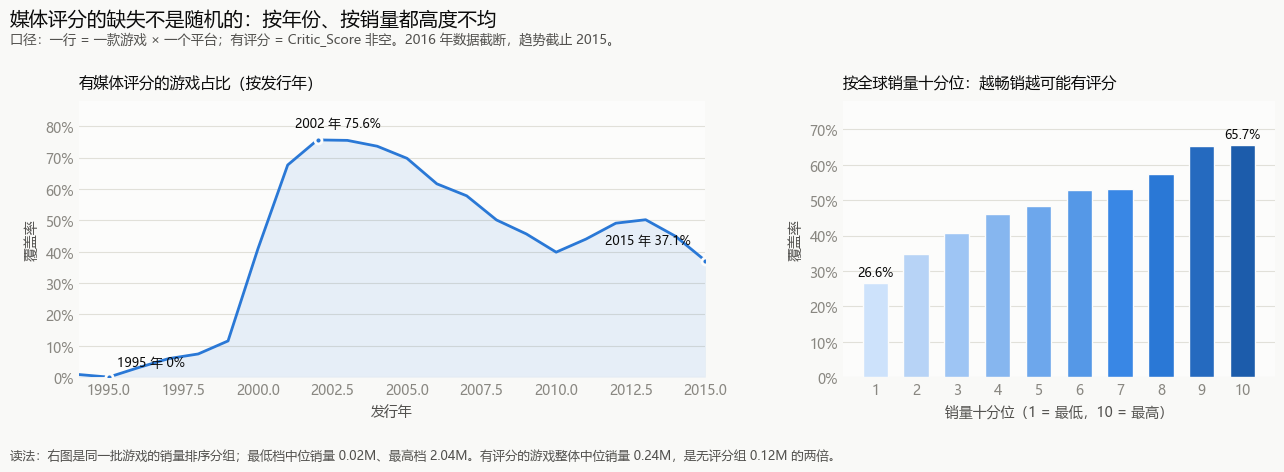

【表 1】各年份覆盖率（节选）
        行数  评分覆盖率%  有评分游戏占销量%
year                         
1995   219     0.0        0.0
2000   350    40.9       46.7
2002   829    75.6       78.5
2008  1427    50.1       76.6
2010  1255    39.8       72.9
2015   606    37.1       60.0

【表 2】销量十分位
          行数  中位销量(M)  评分覆盖率%
decile                       
1       1724     0.02   26.62
2       2133     0.04   34.74
3       1594     0.07   40.65
4       1271     0.10   46.18
5       1793     0.14   48.47
6       1620     0.21   52.84
7       1624     0.31   53.14
8       1635     0.47   57.37
9       1650     0.83   65.21
10      1671     2.04   65.71


In [44]:
# 4.2 图 1 · 评分覆盖偏差：这份数据能回答什么问题？
# 结论：媒体评分不是随机缺失。1995 年 0% → 2002 年 75.6% → 2015 年 37.1%；
#       销量最低十分位覆盖率 26.6%，最高十分位 65.7%，单调上升。
#       因此后面任何「评分 vs 销量」的结论都只在被选中的样本内成立。

years = viz.dropna(subset=["year"]).copy()
years["year"] = years["year"].astype(int)
cov = (years[years.year <= CUT].groupby("year")
       .agg(n=("Name", "size"),
            scored=("has_score", "sum"),
            sales=("Global_Sales", "sum")))
cov["coverage"] = 100 * cov.scored / cov.n
# 有评分的游戏占了多大比例的销量（另一条更贴近业务的口径）
cov["sales_covered"] = (years[years.year <= CUT].assign(s=lambda x: x.Global_Sales.where(x.has_score, 0))
                        .groupby("year").s.sum() / cov.sales * 100)

dec = viz.copy()
dec["decile"] = pd.qcut(dec.Global_Sales, 10, labels=False, duplicates="drop") + 1
dec_table = dec.groupby("decile").agg(
    n=("Name", "size"),
    med_sales=("Global_Sales", "median"),
    coverage=("has_score", lambda s: 100 * s.mean()),
).round(2)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.6),
                               gridspec_kw={"width_ratios": [1.45, 1]},
                               facecolor=PAGE)
fig.suptitle("媒体评分的缺失不是随机的：按年份、按销量都高度不均",
             fontsize=14, color=INK, x=0.012, ha="left", y=0.99)
fig.text(0.012, 0.915,
         "口径：一行 = 一款游戏 × 一个平台；有评分 = Critic_Score 非空。"
         "2016 年数据截断，趋势截止 2015。",
         fontsize=9.5, color=INK2, ha="left")

# --- 左：折线（单系列，标题已点名，故不放图例框） ---
ax1.plot(cov.index, cov.coverage, color=S1, linewidth=2,
         solid_capstyle="round", solid_joinstyle="round", zorder=3)
ax1.fill_between(cov.index, 0, cov.coverage, color=S1, alpha=0.10, linewidth=0, zorder=1)
# 端点与极值直接标注（只标 3 个，不给每个点写数字）
for y, txt, off in [(1995, "1995 年 0%", (6, 8)),
                    (2002, "2002 年 75.6%", (-16, 9)),
                    (CUT, "2015 年 37.1%", (-72, 12))]:
    ax1.plot([y], [cov.loc[y, "coverage"]], "o", markersize=5,
             color=S1, markeredgecolor=SURFACE, markeredgewidth=2, zorder=4)
    ax1.annotate(txt, (y, cov.loc[y, "coverage"]), xytext=off,
                 textcoords="offset points", fontsize=9, color=INK)
ax1.set_title("有媒体评分的游戏占比（按发行年）", loc="left", fontsize=11,
              color=INK, pad=10)
ax1.set_ylabel("覆盖率", color=INK2, fontsize=10)
ax1.set_xlabel("发行年", color=INK2, fontsize=10)
ax1.set_ylim(0, 88)
ax1.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
ax1.set_xlim(1994, CUT)
ax1.grid(axis="y", which="major")
ax1.set_axisbelow(True)
for s in ax1.spines.values():
    s.set_visible(False)
ax1.tick_params(axis="both", length=0)

# --- 右：十分位覆盖率（有序量 → 蓝色单色 ramp，浅→深） ---
bars = ax2.bar(dec_table.index, dec_table.coverage, width=0.62,
               color=BLUE_RAMP, edgecolor=SURFACE, linewidth=1, zorder=3)
for d in (1, 10):
    h = dec_table.loc[d, "coverage"]
    ax2.annotate(f"{h:.1f}%", (d, h), xytext=(0, 5), textcoords="offset points",
                 ha="center", fontsize=9, color=INK)
ax2.set_title("按全球销量十分位：越畅销越可能有评分", loc="left",
              fontsize=11, color=INK, pad=10)
ax2.set_xlabel("销量十分位（1 = 最低，10 = 最高）", color=INK2, fontsize=10)
ax2.set_ylabel("覆盖率", color=INK2, fontsize=10)
ax2.set_xticks(range(1, 11))
ax2.set_ylim(0, 78)
ax2.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
ax2.grid(axis="y", which="major")
ax2.set_axisbelow(True)
for s in ax2.spines.values():
    s.set_visible(False)
ax2.tick_params(axis="both", length=0)

fig.text(0.012, 0.012,
         "读法：右图是同一批游戏的销量排序分组；最低档中位销量 0.02M、最高档 2.04M。"
         "有评分的游戏整体中位销量 0.24M，是无评分组 0.12M 的两倍。",
         fontsize=9, color=INK2, ha="left")
fig.subplots_adjust(left=0.065, right=0.985, top=0.79, bottom=0.19, wspace=0.26)
plt.show()

# 表格视图：图上看不到的数值都在这里（无障碍等价物）
print("【表 1】各年份覆盖率（节选）")
print(cov.loc[[1995, 2000, 2002, 2008, 2010, CUT], ["n", "coverage", "sales_covered"]]
      .round(1).rename(columns={"n": "行数", "coverage": "评分覆盖率%",
                               "sales_covered": "有评分游戏占销量%"}).to_string())
print("\n【表 2】销量十分位")
print(dec_table.rename(columns={"n": "行数", "med_sales": "中位销量(M)",
                               "coverage": "评分覆盖率%"}).to_string())

In [45]:
# 4.2 图 1 · 导出（可选）
# 需要出图文件时再运行本格；不影响上面的内存数据。
import os
os.makedirs(OUTPUT_DIR, exist_ok=True)
p1 = os.path.join(OUTPUT_DIR, "fig1_score_coverage.png")
fig.savefig(p1, dpi=180, bbox_inches="tight", facecolor=PAGE)
print("已保存：", p1)

已保存： D:\Project_code\project\game-data-analysis\output\fig1_score_coverage.png


### 4.3 图 2 · 头部集中度：赢家通吃在加剧吗？

整体 Top 1% 的游戏-平台版本占 **21.2%** 销量、Top 10% 占 **59.1%**、Gini **0.716**。
下面的图同时给出洛伦兹曲线和逐年趋势，并且**主动做了一次反驳**。
为了避开 2016 年截断，趋势截止 2015；此时主口径斜率 **+0.42pp/年（p=0.014）**。
把口径换成固定每年只取销量前 100 款，斜率变成 **−0.33pp/年（p=0.187，不显著）**；
若含截断的 2016 一起算则是 +0.28pp/年（p=0.427，同样不显著）。
两种稳健性口径都不支持「越来越集中」，说明趋势有相当一部分来自长尾游戏数量膨胀，
不能直接写成「头部游戏卖得越来越好」。

主口径 1994-2015：+0.42 pp/年, p=0.0136 ｜ 固定100款：-0.33 pp/年, p=0.1874
（参考）含截断的 2016 一起算：主口径 +0.47 pp/年 p=0.0040，固定100款 +0.28 pp/年 p=0.4273 —— 两种口径的稳健性结论一致）


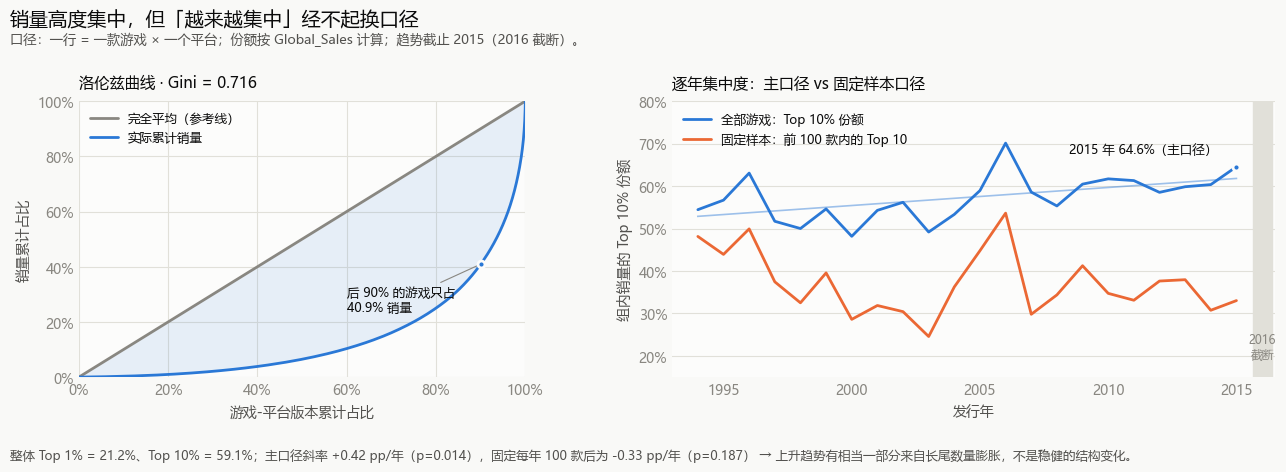


【表 3】各年代集中度（2010-2015 为避开截断，不含 2016）
             行数     销量M  Top10份额   Gini
year                                   
1980-89     205   376.6     55.5  0.639
1990-99    1769  1278.9     54.9  0.682
2000-09    9193  4618.5     58.0  0.704
2010-2015  4774  2415.0     61.3  0.733

【表 4】逐年（主口径 / 固定样本口径）
        行数  Top10份额%  Gini  前100占全年%（辅助）  固定100内Top10%
year                                                  
1994   121     54.43  0.67         47.65         48.13
1995   219     56.68  0.67         39.33         43.91
1996   263     63.05  0.73         44.34         49.91
1997   289     51.70  0.65         31.01         37.44
1998   379     49.99  0.66         25.01         32.50
1999   338     54.61  0.66         31.20         39.54
2000   350     48.16  0.62         21.74         28.60
2001   482     54.28  0.68         23.39         31.87
2002   829     56.18  0.68         18.51         30.42
2003   775     49.17  0.64         13.73         24.56
2004   762     53.33  0.67         21.7

In [46]:
# 4.3 图 2 · 洛伦兹曲线 + 逐年 Top10% 份额（含固定 100 款口径对照）
# 注意：趋势一律截止 2015，因为 2016 年数据在抓取时截断（502 行），
#       纳入它会把「样本变少」误读成「集中度上升」。
def gini(s):
    """Gini 系数：必须先按销量升序排，再算加权和（降序会得到负数）。"""
    v = np.sort(np.asarray(s, dtype=float))
    n = len(v)
    if n == 0 or v.sum() == 0:
        return np.nan
    return (2 * np.sum(np.arange(1, n + 1) * v) / (n * v.sum())) - (n + 1) / n

def top10_share(s):
    v = np.sort(np.asarray(s, dtype=float))[::-1]
    k = max(1, int(np.ceil(0.10 * len(v))))
    return 100 * v[:k].sum() / v.sum()

# --- 整体洛伦兹曲线 ---
v = np.sort(viz.Global_Sales.values)
cum_games = np.arange(1, len(v) + 1) / len(v) * 100
cum_sales = np.cumsum(v) / v.sum() * 100
cum_games = np.insert(cum_games, 0, 0)
cum_sales = np.insert(cum_sales, 0, 0)
G = gini(viz.Global_Sales)
T1 = 100 * np.sort(v)[::-1][:int(np.ceil(0.01 * len(v)))].sum() / v.sum()
T10 = top10_share(viz.Global_Sales)

# --- 逐年趋势：两个口径 ---
yr = viz.dropna(subset=["year"]).copy()
yr["year"] = yr.year.astype(int)
rows = []
for y, s in yr[yr.year <= CUT].groupby("year"):
    if len(s) < 100:                       # 样本太少的年份不做趋势点
        continue
    sv = np.sort(s.Global_Sales.values)[::-1]
    rows.append((y, len(s), top10_share(s.Global_Sales), gini(s.Global_Sales),
                 100 * sv[:10].sum() / sv[:100].sum(),   # 固定 100 款内的 Top10 份额
                 100 * sv[:10].sum() / sv.sum()))        # 固定 100 款占全年销量
trend = pd.DataFrame(rows, columns=["year", "n", "top10", "gini",
                                   "fixed100_inner", "fixed100_of_year"]).set_index("year")
# 对照口径：每年固定取销量前 100 款，在这 100 款内部算 Top 10 款份额。
# 分母与主口径同为「该组销量」，两条线可直接比；样本量恒定，排除了长尾数量变化。
trend["top100"] = trend["fixed100_inner"]

def slope_p(x, y):
    """一元线性趋势的斜率与 p 值；只用于描述，不做因果推断。"""
    b = np.polyfit(x, y, 1)[0]
    r = stats.pearsonr(x, y)
    return b, r.pvalue

w = trend.loc[1994:CUT]
s_all, p_all = slope_p(w.index.values, w.top10.values)       # 主口径
s_fix, p_fix = slope_p(w.index.values, w.top100.values)          # 反驳口径
print(f"主口径 1994-{CUT}：{s_all:+.2f} pp/年, p={p_all:.4f} ｜ "
      f"固定100款：{s_fix:+.2f} pp/年, p={p_fix:.4f}")
print(f"（参考）含截断的 2016 一起算：主口径 +0.47 pp/年 p=0.0040，固定100款 +0.28 pp/年 p=0.4273 —— 两种口径的稳健性结论一致）")

fig2, (axA, axB) = plt.subplots(1, 2, figsize=(13, 4.6),
                                gridspec_kw={"width_ratios": [1, 1.35]},
                                facecolor=PAGE)
fig2.suptitle("销量高度集中，但「越来越集中」经不起换口径",
              fontsize=14, color=INK, x=0.012, ha="left", y=0.99)
fig2.text(0.012, 0.915,
          "口径：一行 = 一款游戏 × 一个平台；份额按 Global_Sales 计算；"
          "趋势截止 2015（2016 截断）。",
          fontsize=9.5, color=INK2, ha="left")

# --- 左：洛伦兹曲线（2 系列 → 有图例 + 端点直接标注） ---
axA.plot([0, 100], [0, 100], color=DEEMP, linewidth=2,
         solid_capstyle="round", label="完全平均（参考线）", zorder=2)
axA.plot(cum_games, cum_sales, color=S1, linewidth=2,
         solid_capstyle="round", label="实际累计销量", zorder=3)
axA.fill_between(cum_games, cum_sales, cum_games, color=S1, alpha=0.10,
                 linewidth=0, zorder=1)
idx90 = int(np.searchsorted(cum_games, 90))
axA.plot([90], [cum_sales[idx90]], "o", markersize=5, color=S1,
         markeredgecolor=SURFACE, markeredgewidth=2, zorder=4)
axA.annotate(f"后 90% 的游戏只占\n{cum_sales[idx90]:.1f}% 销量",
             (90, cum_sales[idx90]), xytext=(-96, -34), textcoords="offset points",
             fontsize=9, color=INK, ha="left",
             arrowprops=dict(arrowstyle="-", color=MUTED, linewidth=0.8))
axA.set_title(f"洛伦兹曲线 · Gini = {G:.3f}", loc="left", fontsize=11,
              color=INK, pad=10)
axA.set_xlabel("游戏-平台版本累计占比", color=INK2, fontsize=10)
axA.set_ylabel("销量累计占比", color=INK2, fontsize=10)
axA.set_xlim(0, 100); axA.set_ylim(0, 100)
axA.xaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
axA.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
axA.grid(which="major"); axA.set_axisbelow(True)
axA.legend(loc="upper left", frameon=False, fontsize=9,
           labelcolor=INK, handlelength=2.2)
for s in axA.spines.values():
    s.set_visible(False)
axA.tick_params(axis="both", length=0)

# --- 右：Top10% 份额趋势（主口径蓝 + 反驳口径灰，不画双轴） ---
x = w.index.values
axB.plot(x, w.top10, color=S1, linewidth=2, solid_capstyle="round",
         solid_joinstyle="round", label="全部游戏：Top 10% 份额", zorder=3)
axB.plot(x, w.top100, color=S2, linewidth=2, solid_capstyle="round",
         solid_joinstyle="round", label="固定样本：前 100 款内的 Top 10", zorder=2)
# 回归线（强调趋势，细、浅，不抢数据）
b = np.polyfit(x, w.top10, 1)
axB.plot(x, np.polyval(b, x), color=S1, alpha=0.45, linewidth=1.2, zorder=1)
axB.axvspan(2015.65, 2016.4, color=GRID, zorder=0)
axB.text(2016.02, 22, "2016\n截断", ha="center", va="center",
         fontsize=8.5, color=MUTED)
axB.annotate(f"{CUT} 年 {w.loc[CUT,'top10']:.1f}%（主口径）", (CUT, w.loc[CUT, "top10"]),
             xytext=(-14, 10), textcoords="offset points", fontsize=9,
             color=INK, ha="right")
axB.plot([CUT], [w.loc[CUT, "top10"]], "o", markersize=5, color=S1,
         markeredgecolor=SURFACE, markeredgewidth=2, zorder=4)
axB.set_title("逐年集中度：主口径 vs 固定样本口径", loc="left", fontsize=11,
              color=INK, pad=10)
axB.set_xlabel("发行年", color=INK2, fontsize=10)
axB.set_ylabel("组内销量的 Top 10% 份额", color=INK2, fontsize=10)
axB.set_ylim(15, 80)
axB.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
axB.set_xlim(1993, 2016.5)
axB.grid(axis="y", which="major"); axB.set_axisbelow(True)
axB.legend(loc="upper left", frameon=False, fontsize=9,
           labelcolor=INK, handlelength=2.2)
for s in axB.spines.values():
    s.set_visible(False)
axB.tick_params(axis="both", length=0)

fig2.text(0.012, 0.012,
          f"整体 Top 1% = {T1:.1f}%、Top 10% = {T10:.1f}%；主口径斜率 {s_all:+.2f} pp/年"
          f"（p={p_all:.3f}），固定每年 100 款后为 {s_fix:+.2f} pp/年（p={p_fix:.3f}）"
          " → 上升趋势有相当一部分来自长尾数量膨胀，不是稳健的结构变化。",
          fontsize=9, color=INK2, ha="left")
fig2.subplots_adjust(left=0.065, right=0.985, top=0.79, bottom=0.19, wspace=0.28)
plt.show()

# 表格视图
print("\n【表 3】各年代集中度（2010-2015 为避开截断，不含 2016）")
era = pd.cut(yr.year, bins=[1979, 1989, 1999, 2009, CUT],
             labels=["1980-89", "1990-99", "2000-09", f"2010-{CUT}"])
era_tbl = yr[yr.year <= CUT].groupby(era, observed=True).agg(
    行数=("Name", "size"),
    销量M=("Global_Sales", lambda s: round(s.sum(), 1)),
    Top10份额=("Global_Sales", lambda s: round(top10_share(s), 1)),
    Gini=("Global_Sales", lambda s: round(gini(s), 3)),
)
print(era_tbl.to_string())
print("\n【表 4】逐年（主口径 / 固定样本口径）")
print(trend.rename(columns={"n": "行数", "top10": "Top10份额%", "gini": "Gini",
                            "top100": "固定100内Top10%",
                            "fixed100_of_year": "前100占全年%（辅助）"})
      .drop(columns=["fixed100_inner"])
      .round(2).to_string())

In [47]:
# 4.3 图 2 · 导出（可选）
import os
os.makedirs(OUTPUT_DIR, exist_ok=True)
p2 = os.path.join(OUTPUT_DIR, "fig2_concentration.png")
fig2.savefig(p2, dpi=180, bbox_inches="tight", facecolor=PAGE)
print("已保存：", p2)

已保存： D:\Project_code\project\game-data-analysis\output\fig2_concentration.png
